# Performing DEG Pathway analysis (limma, R) on Pseudobulking DC1s from atlas
* Ovarian cancer samples only
*  dataframes made previously (2026-09-29_OC_cDC2subset_PseudobulkingSampleType.jpynb), separate for each DC2 subset and each has seperate metadata file
* Following code from NR 2025-02-12_Pseudo_Cancer_DEGS.
* Looking at DC2 subsets only
* Use the R environment (R_env)

In [23]:
library(limma)
library(edgeR)
library(dplyr)
library(tidyverse)

── Attaching core tidyverse packages ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.1     ✔ readr     2.2.0
✔ ggplot2   4.0.2     ✔ stringr   1.6.0
✔ lubridate 1.9.5     ✔ tibble    3.3.1
✔ purrr     1.2.1     ✔ tidyr     1.3.2
── Conflicts ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:

# set directory
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/NewDC2subsets_Analysis/DC2_Pseudobulk/")

In [4]:
list.files()

[1] "pseudobulk_dc2_data.csv"      "pseudobulk_dc3_data.csv"     
 [3] "pseudobulk_IL18_data.csv"     "pseudobulk_ISG_data.csv"     
 [5] "pseudobulk_metadata_dc2.csv"  "pseudobulk_metadata_dc3.csv" 
 [7] "pseudobulk_metadata_IL18.csv" "pseudobulk_metadata_ISG.csv" 
 [9] "pseudobulk_metadata_SIK3.csv" "pseudobulk_SIK3_data.csv"

In [6]:
#read in csv files for pseudobulked data
#read only the 5 DC2 subsets with more than 20 cells per condition(primary vs metastatic)

pseudobulk_IL18 <- read.csv("pseudobulk_IL18_data.csv")
pseudobulk_ISG <- read.csv("pseudobulk_ISG_data.csv")
pseudobulk_SIK3 <- read.csv("pseudobulk_SIK3_data.csv")
pseudobulk_dc2 <- read.csv("pseudobulk_dc2_data.csv")
pseudobulk_dc3 <- read.csv("pseudobulk_dc3_data.csv")


In [7]:
#read in csv files for metadata

IL18_metadata <- read.csv("pseudobulk_metadata_IL18.csv")
ISG_metadata <- read.csv("pseudobulk_metadata_ISG.csv")
SIK3_metadata <- read.csv("pseudobulk_metadata_SIK3.csv")
dc2_metadata <- read.csv("pseudobulk_metadata_dc2.csv")
dc3_metadata <- read.csv("pseudobulk_metadata_dc3.csv")

## Load data - DC2 subset IL-18

In [9]:
#load data
sampleinfo <- read.csv("pseudobulk_metadata_IL18.csv", row.names =1)
head(sampleinfo)

,sample_type_major2
,<chr>
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_BOWEL,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_INFRACOLIC_OMENTUM,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_PELVIC_PERITONEUM,metastatic tumour
GSE180661_SPECTRUM-OV-009_S1_CD45P_RIGHT_UPPER_QUADRANT,metastatic tumour
GSE180661_SPECTRUM-OV-014_S1_CD45P_BOWEL,metastatic tumour


In [10]:
dim(sampleinfo)

[1] 68  1

In [15]:
cts_il18 <- read.csv("pseudobulk_IL18_data.csv")
head(cts_il18)

,X,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL,GSE180661_SPECTRUM.OV.009_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.009_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.009_S1_CD45P_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.014_S1_CD45P_BOWEL,GSE180661_SPECTRUM.OV.014_S1_CD45P_LEFT_OVARY,GSE180661_SPECTRUM.OV.014_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.022_S1_CD45P_ASCITES,⋯,GSE180661_SPECTRUM.OV.115_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.115_S1_CD45P_RIGHT_ADNEXA,GSE180661_SPECTRUM.OV.118_S1_CD45P_LEFT_ADNEXA,GSE180661_SPECTRUM.OV.118_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.118_S1_CD45P_RIGHT_ADNEXA,GSE184880_HGSOC_Cancer1,GSE184880_HGSOC_Cancer7,GSE184880_Healthy_Norm3,GSE213243_HGSOC_ascites,GSE217517_HGSOC_pt2
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,KLHL17,-0.1125081,-0.2831936,-0.1437022,-0.2761633,7.4777655,11.6354090,5.483738,-1.040186,-0.1355669,⋯,-0.5079945,-0.4831628,9.6768074,-0.2146680,-0.4901653,-0.3126361,-0.31047127,-0.1898368,-0.3319154,-0.1551964
2,HES4,-0.2649864,-1.7007686,-0.9779288,-1.4995446,-0.8168666,-9.1542802,-4.247257,-1.126514,-0.4688702,⋯,-2.1378174,-1.6836270,-1.4399777,-0.5462781,-1.9668876,-0.2312666,0.03742275,-0.5773711,-0.6272758,-0.4512505
3,ISG15,0.7779065,4.3788717,4.5730731,7.4045567,3.4370723,7.7360643,-1.695497,3.204520,2.6137026,⋯,-1.4717386,-1.0901660,0.9132879,1.9775658,0.2950509,-0.3338319,0.08980434,0.5850886,-1.1495952,0.9129194
4,AGRN,-0.1790436,3.0553820,-0.4977805,-0.7267220,-0.3813677,0.7035992,-2.514355,5.403947,-0.2981938,⋯,-1.0847126,1.5656882,-0.8990469,-0.3716557,-1.1354640,-0.3029635,-0.37974578,-0.3063883,-0.4688194,1.7637798
5,TNFRSF18,-0.2460078,-0.9739197,-0.7052251,-0.9935963,-0.5202888,-5.9837349,-2.579263,-2.135563,-0.4768122,⋯,-1.2353086,-1.1955583,-1.1358223,-0.4664193,-1.3492457,-0.2465032,-0.20647621,-0.2628269,-0.5039502,-0.5389408
6,TNFRSF4,-0.2486940,-1.0737704,-0.7405825,-1.0763419,-0.5762799,-5.1412880,-2.964110,-2.342563,-0.4808185,⋯,-1.3428428,-1.2590829,-1.1463666,-0.4674854,-1.3998288,-0.2074768,-0.10233145,-0.2893519,-0.4830124,-0.6751487


In [16]:
dim(cts_il18)

[1] 2001   69

In [25]:
# set genes variables
#genes <- data.frame(Symbol = row.names(cts_il18))
genes <- cts_il18 %>% 
  column_to_rownames(var = "X")

In [26]:
genes

,GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL,GSE180661_SPECTRUM.OV.009_S1_CD45P_INFRACOLIC_OMENTUM,GSE180661_SPECTRUM.OV.009_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.009_S1_CD45P_RIGHT_UPPER_QUADRANT,GSE180661_SPECTRUM.OV.014_S1_CD45P_BOWEL,GSE180661_SPECTRUM.OV.014_S1_CD45P_LEFT_OVARY,GSE180661_SPECTRUM.OV.014_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.022_S1_CD45P_ASCITES,GSE180661_SPECTRUM.OV.022_S1_CD45P_LEFT_ADNEXA,⋯,GSE180661_SPECTRUM.OV.115_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.115_S1_CD45P_RIGHT_ADNEXA,GSE180661_SPECTRUM.OV.118_S1_CD45P_LEFT_ADNEXA,GSE180661_SPECTRUM.OV.118_S1_CD45P_PELVIC_PERITONEUM,GSE180661_SPECTRUM.OV.118_S1_CD45P_RIGHT_ADNEXA,GSE184880_HGSOC_Cancer1,GSE184880_HGSOC_Cancer7,GSE184880_Healthy_Norm3,GSE213243_HGSOC_ascites,GSE217517_HGSOC_pt2
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KLHL17,-0.11250811,-0.2831936,-0.1437022,-0.2761633,7.4777655,11.6354090,5.4837381,-1.0401861,-0.1355669,-0.09092442,⋯,-0.50799455,-0.4831628,9.6768074,-0.2146680,-0.4901653,-0.31263606,-0.31047127,-0.18983684,-0.33191540,-0.15519639
HES4,-0.26498642,-1.7007686,-0.9779288,-1.4995446,-0.8168666,-9.1542802,-4.2472567,-1.1265137,-0.4688702,-0.25983860,⋯,-2.13781738,-1.6836270,-1.4399777,-0.5462781,-1.9668876,-0.23126659,0.03742275,-0.57737114,-0.62727583,-0.45125045
ISG15,0.77790649,4.3788717,4.5730731,7.4045567,3.4370723,7.7360643,-1.6954969,3.2045198,2.6137026,1.75703147,⋯,-1.47173856,-1.0901660,0.9132879,1.9775658,0.2950509,-0.33383185,0.08980434,0.58508864,-1.14959522,0.91291937
AGRN,-0.17904358,3.0553820,-0.4977805,-0.7267220,-0.3813677,0.7035992,-2.5143549,5.4039469,-0.2981938,-0.15975916,⋯,-1.08471264,1.5656882,-0.8990469,-0.3716557,-1.1354640,-0.30296351,-0.37974578,-0.30638829,-0.46881943,1.76377984
TNFRSF18,-0.24600776,-0.9739197,-0.7052251,-0.9935963,-0.5202888,-5.9837349,-2.5792631,-2.1355626,-0.4768122,-0.24793538,⋯,-1.23530865,-1.1955583,-1.1358223,-0.4664193,-1.3492457,-0.24650318,-0.20647621,-0.26282691,-0.50395023,-0.53894081
TNFRSF4,-0.24869402,-1.0737704,-0.7405825,-1.0763419,-0.5762799,-5.1412880,-2.9641099,-2.3425630,-0.4808185,-0.25706351,⋯,-1.34284276,-1.2590829,-1.1463666,-0.4674854,-1.3998288,-0.20747679,-0.10233145,-0.28935189,-0.48301238,-0.67514870
PRKCZ,6.63320087,-0.6605223,-0.4525740,-0.6328759,-0.3287154,3.8168112,-2.0462065,5.8042277,-0.2760261,-0.14602735,⋯,-0.78441062,-0.7563896,6.5182439,-0.2711687,-0.9029275,-0.05751427,-0.25272618,-0.14782098,8.13084679,-0.43240583
MORN1,-0.09505118,-0.3947841,-0.2411755,-0.3748033,-0.2065794,-2.7315670,-1.2181362,-0.9946615,-0.1541794,-0.08760752,⋯,-0.54535065,-0.4815766,-0.4273551,-0.1846667,-0.5325669,-0.15491462,-0.10488140,-0.15505121,-0.23921111,-0.26209115
ACOT7,-0.23670594,-1.2794102,-0.8966380,-1.1285217,1.0170265,3.0877754,-2.1791017,-2.3379703,1.9796562,-0.26681829,⋯,0.29024308,0.9324493,-1.5443416,-0.5712953,-2.1140325,-0.04296990,1.20861134,2.08719205,-0.20620493,0.23884129


In [27]:
# create DGEList variable
y <- DGEList(counts = cts_il18, genes = genes)

Setting first column of `counts` as gene annotation.



ERROR: Error in DGEList.default(counts = counts, lib.size = lib.size, norm.factors = norm.factors, : Negative counts not allowed


In [16]:
head(y)

An object of class "DGEList"
$counts
  GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
1                                              0
2                                              0
3                                              0
4                                              0
5                                              5
6                                              0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
1                                                        0
2                                                        0
3                                                        0
4                                                        1
5                                                        4
6                                                        0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
1                                                 0
2                                                 0
3                                                 0
4                                                 0
5                                                 1
6                                                 0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
1                                                         0
2                                                         0
3                                                         1
4                                                         0
5                                                         1
6                                                         0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
1                                                       0
2                                                       0
3                                                       0
4                                                       0
5                                                       3
6                                                       0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
1                                                  1
2                                                  0
3                                                  0
4                                                  0
5                                                  0
6                                                  0
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
1                                                          0
2                                                          0
3                                                          0
4                                                          0
5                                                          2
6                                                          0
  GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
1                                        0
2                                        0
3                                        0
4                                        0
5                                        3
6                                        0
  GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
1                                                     1
2                                                     0
3                                                     0
4                                                     0
5                                                     0
6                                                     0
  GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
1                                        0
2                                        2
3                                        1
4                                        0
5                                        7
6                                        1
  GSE180661_SPECTRUM.OV.009_S1_CD45P_INFRACOLIC_OMENTUM
1                                                     0
2                                                     1
3                                                     0
4

In [17]:
dim(y)

[1] 15074   170

### Filtering:

In [18]:
# Keep genes with total counts more than 50.
A <- rowSums(y$counts)
isexpr <- A > 50

In [19]:
# Keep only genes with defined annotation:
hasannot <- rowSums(is.na(y$genes)) == 0

In [20]:
y <- y[isexpr & hasannot, , keep.lib.size = FALSE]
dim(y)

[1] 9997  170

### Normalise data

In [21]:
y <- calcNormFactors(y)
head(y)

An object of class "DGEList"
$counts
  GSE180661_SPECTRUM.OV.002_S1_CD45P_RIGHT_OVARY
2                                              0
5                                              5
6                                              0
7                                              0
8                                              0
9                                              8
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_INFRACOLIC_OMENTUM
2                                                        0
5                                                        4
6                                                        0
7                                                        0
8                                                        0
9                                                      184
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_ADNEXA
2                                                 0
5                                                 1
6                                                 0
7                                                 0
8                                                 1
9                                                40
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_LEFT_UPPER_QUADRANT
2                                                         0
5                                                         1
6                                                         0
7                                                         0
8                                                         0
9                                                        18
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_PELVIC_PERITONEUM
2                                                       0
5                                                       3
6                                                       0
7                                                       0
8                                                       1
9                                                     139
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_ADNEXA
2                                                  0
5                                                  0
6                                                  0
7                                                  0
8                                                  0
9                                                  6
  GSE180661_SPECTRUM.OV.003_S1_UNSORTED_RIGHT_UPPER_QUADRANT
2                                                          0
5                                                          2
6                                                          0
7                                                          1
8                                                          0
9                                                          7
  GSE180661_SPECTRUM.OV.008_S1_CD45P_BOWEL
2                                        0
5                                        3
6                                        0
7                                        0
8                                        6
9                                      118
  GSE180661_SPECTRUM.OV.008_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     0
5                                                     0
6                                                     0
7                                                     0
8                                                     0
9                                                     4
  GSE180661_SPECTRUM.OV.009_S1_CD45P_BOWEL
2                                        2
5                                        7
6                                        1
7                                        2
8                                        6
9                                      972
  GSE180661_SPECTRUM.OV.009_S1_CD45P_INFRACOLIC_OMENTUM
2                                                     1
5                                                     4
6                                                     0
7

### Multi-dimensional scaling (MDS) plot to visualise relationship between samples

In [22]:
library(RColorBrewer)

In [23]:
# create vector of colours for sample types
sample_types <- unique(sampleinfo$sample_type_major2)
colors <- brewer.pal(n = length(sample_types), name = "Accent")

In [24]:
# set each sample type to a colour
sample_colors <- setNames(colors, sample_types)

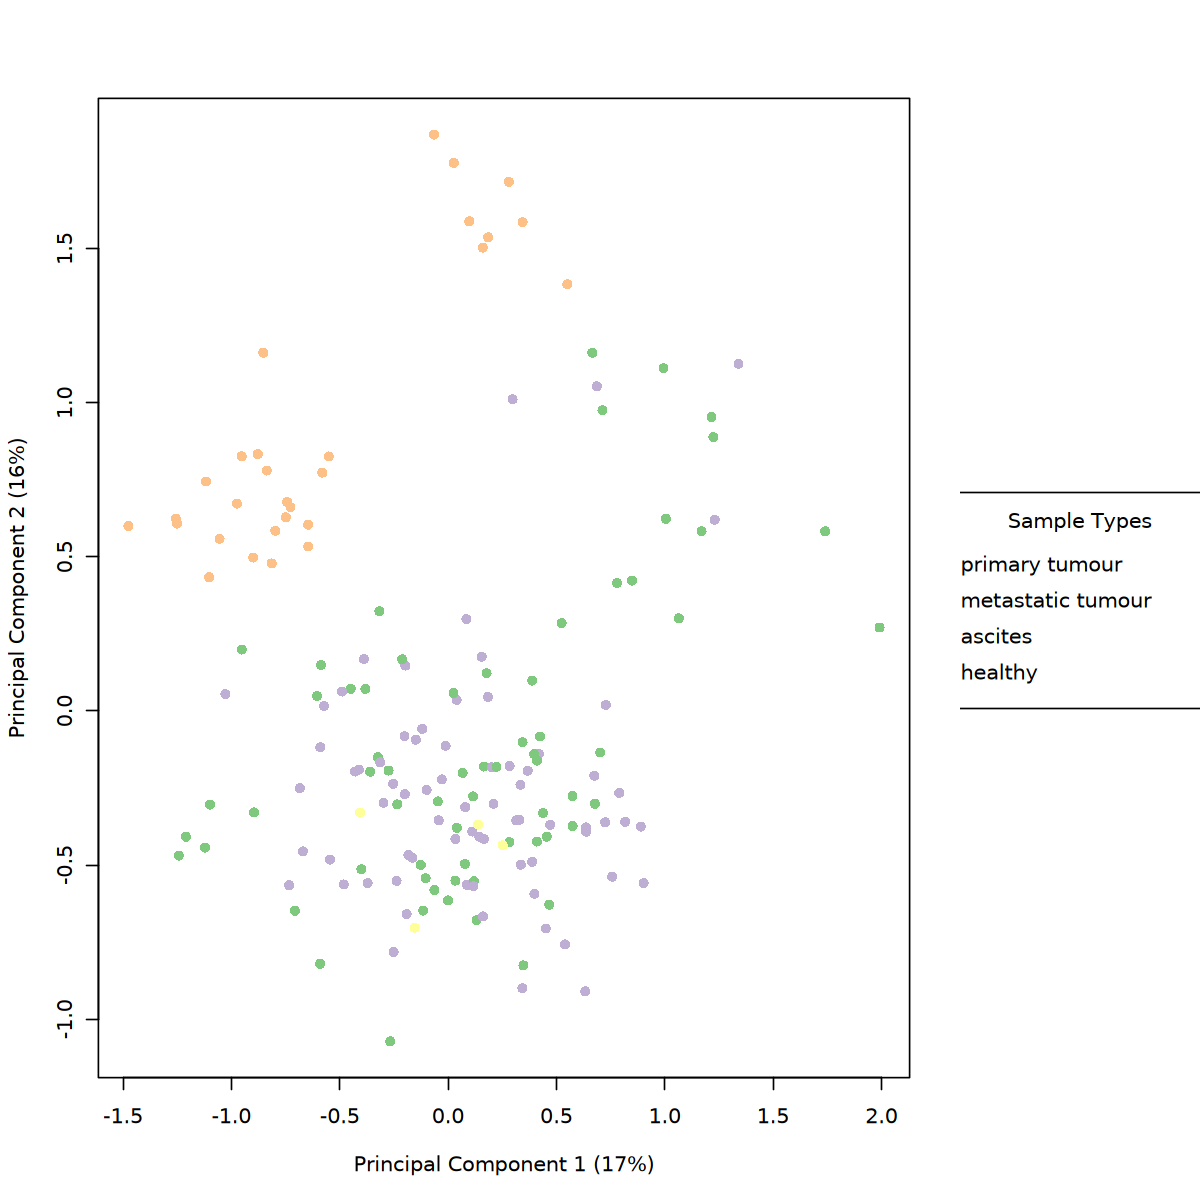

In [25]:
options(repr.plot.height=10, repr.plot.width=10)
layout(matrix(1:2, ncol = 2), widths = c(4, 1))  # Allocate space for the plot and legend

# Generate the MDS plot
plotMDS(y, 
        #labels = sampleinfo$sample_type_major2, 
        labels = NULL,
        col = sample_colors[sampleinfo$sample_type_major2], 
        pch = 16,
        top = 50, 
        gene.selection = "common", 
        prior.count = 5)

# Add a legend
par(mar = c(0, 0, 0, 0))  # Remove margins for the legend area
plot.new()               
legend("center",                        
       legend = sample_types,                 
       col = colors,                        
       pch = 16,                               
       title = "Sample Types")               
     

## Set Up Model

In [26]:
# setup model
design <- model.matrix(~ 0 + sample_type_major2, data = sampleinfo)

In [27]:
colnames(design) <- c("primary tumour","metastatic tumour","ascites","healthy")

In [28]:
head(design)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_RIGHT_ADNEXA,0,0,0,1


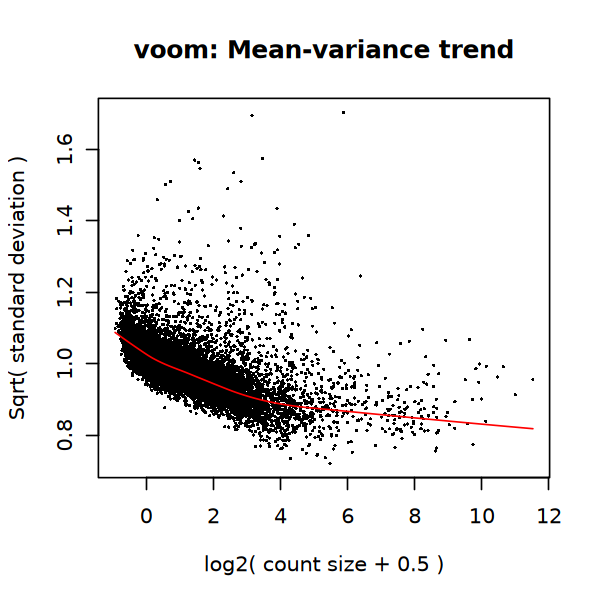

In [29]:
#voom - see here for good v bad voom plot: https://ucdavis-bioinformatics-training.github.io/2018-June-RNA-Seq-Workshop/thursday/DE.html
options(repr.plot.height=5, repr.plot.width=5)
v <- voom(y, design, plot = TRUE)

In [30]:
# lmFit
fit <- lmFit(v, design)

## Contrast - compare primary to the rest

In [31]:
#duplicate data
design2 <- design
head(design2)

,primary tumour,metastatic tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_RIGHT_ADNEXA,0,0,0,1


### Primary vs Metastatic set as design 1 and 2

In [32]:
# Rename columns to remove the spaces
colnames(design2)[1] <- "primary_tumour"
colnames(design2)[2] <- "metastatic_tumour"

In [33]:
head(design2)

,primary_tumour,metastatic_tumour,ascites,healthy
GSE180661_SPECTRUM-OV-002_S1_CD45P_RIGHT_OVARY,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_INFRACOLIC_OMENTUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_ADNEXA,0,0,0,1
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_LEFT_UPPER_QUADRANT,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_PELVIC_PERITONEUM,0,0,1,0
GSE180661_SPECTRUM-OV-003_S1_UNSORTED_RIGHT_ADNEXA,0,0,0,1


In [ ]:
`````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````# make contrast matrix, apply contrasts, and fit the model 
contrast.matrix <- makeContrasts(primary_tumour - (metastatic_tumour + healthy + ascites), levels=design2) #compare primary to rest
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)`````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````````

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [35]:
# check the results
tt1 <- topTable(fit2, coef=1, adjust="BH", number = Inf) #Benjamini-Hochberg (BH) procedure is a statistical method used in multiple hypothesis testing to control the False Discovery Rate (FDR)

In [36]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)
head(tt1)
     

       primary_tumour - (metastatic_tumour + healthy + ascites)
Down                                                       9997
NotSig                                                        0
Up                                                            0

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
15065,MT-CO2,15065,-27.15077,13.18654,-79.52932,9.401439e-154,9.398619e-150,318.1323
15064,MT-CO1,15064,-27.62640,13.57086,-71.10797,2.509446e-144,9.574322e-141,301.3222
10143,TPT1,10143,-23.64949,12.07730,-71.05816,2.873159e-144,9.574322e-141,299.6445
11883,RPL13,11883,-23.79546,12.09481,-70.39608,1.751110e-143,4.376462e-140,298.2767
1925,TMSB10,1925,-25.61169,13.02733,-66.25506,2.054290e-138,4.107348e-135,289.4144
15074,MT-CYB,15074,-26.02548,12.38237,-65.40601,2.442213e-137,4.069134e-134,287.6146


## Compare primary to each other state

In [37]:
# make contrast matrix, apply contrasts, and fit the model 
contrast.matrix <- makeContrasts(primary_tumour-metastatic_tumour,primary_tumour-healthy,primary_tumour-ascites, levels=design2) #compare primary to every other individually
fit2 <- contrasts.fit(fit, contrast.matrix)
fit2 <- eBayes(fit2)
    

Warning message in contrasts.fit(fit, contrast.matrix):
“row names of contrasts don't match col names of coefficients”


In [38]:
# check the results
tt1 <- topTable(fit2, coef=1, adjust="BH", number = Inf) #primary_tumour-metastatic_tumour
tt2 <- topTable(fit2, coef=2, adjust="BH", number = Inf) #primary_tumour-healthy
tt3 <- topTable(fit2, coef=3, adjust="BH", number = Inf) #primary_tumour-ascites

In [39]:
# determine which genes significant DEGs
results <- decideTests(fit2)
summary(results)


       primary_tumour - metastatic_tumour primary_tumour - healthy
Down                                  798                     2639
NotSig                               8879                     5643
Up                                    320                     1715
       primary_tumour - ascites
Down                       2095
NotSig                     6562
Up                         1340

In [40]:
head(tt1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
14192,FOSB,14192,-6.296804,7.277445,-10.322329,2.602494e-20,2.601713e-16,35.15871
5834,COL1A2,5834,-5.243841,2.816614,-8.639858,1.760841e-15,8.801562e-12,24.31056
2150,CXCR4,2150,-4.698578,7.427939,-7.388013,3.917982e-12,1.305602e-08,17.13263
9530,NR4A1,9530,-4.245668,7.017105,-7.087584,2.267957e-11,4.699024e-08,15.45282
12509,COL1A1,12509,-4.794828,2.971580,-7.081416,2.350217e-11,4.699024e-08,15.33050
1265,RGS1,1265,-4.721053,7.965060,-6.953391,4.903455e-11,8.169973e-08,14.72184


In [41]:
# 1. Assign the column values to row names
rownames(tt1) <- tt1$X
rownames(tt2) <- tt2$X
rownames(tt3) <- tt3$X

In [42]:
# select top 250 up, and 250 down genes from tt1
up_genes_tt1 <- tt1 %>% filter(logFC > 0 & adj.P.Val < 0.05) %>% select(Symbol) %>% head(500) %>% unlist %>% as.character
down_genes_tt1 <- tt1 %>% filter(logFC < 0 & adj.P.Val < 0.05) %>% select(Symbol) %>% head(500) %>% unlist %>% as.character

In [43]:
plot_genes_tt1 <- c(up_genes_tt1, down_genes_tt1)

In [48]:
# select top 250 up, and 250 down genes from tt1
up_genes_tt1 <- tt1 %>% filter(logFC > 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character
down_genes_tt1 <- tt1 %>% filter(logFC < 0 & adj.P.Val < 0.05) %>% select(X) %>% head(500) %>% unlist %>% as.character

In [49]:
up_genes_tt1

[1] "LY96"      "FLOT1"     "GCA"       "REST"      "MIF4GD"    "RAB32"    
  [7] "CST7"      "TMEM59"    "ARL6IP5"   "TMEM219"   "MRPS34"    "SLC46A3"  
 [13] "LRRCC1"    "CCNI"      "SPINT2"    "CCPG1"     "XCR1"      "PCMTD1"   
 [19] "ATP6V0E1"  "RCN2"      "ERLEC1"    "FUCA1"     "PTGES2"    "PTPN1"    
 [25] "UFC1"      "PARP1"     "NAAA"      "MAGEF1"    "S100A11"   "CTSH"     
 [31] "NUBPL"     "MFF"       "GAS6"      "XRN2"      "SEC11A"    "TMEM9B"   
 [37] "SEPHS2"    "P2RY6"     "PON2"      "CFDP1"     "DCTPP1"    "COMMD8"   
 [43] "ARPC2"     "SDHA"      "ARF5"      "CLNK"      "ITGB1"     "SERPINB1" 
 [49] "MRPL54"    "PNMA1"     "ZDHHC24"   "PTMS"      "RHOA"      "DUSP23"   
 [55] "ADAP2"     "UQCRFS1"   "STX17"     "EVL"       "M6PR"      "PLEKHB2"  
 [61] "RABAC1"    "SMARCA5"   "EIF3F"     "TOMM7"     "NUP50"     "HLA-E"    
 [67] "CD72"      "MAP3K13"   "SOD1"      "PRCP"      "CCDC127"   "NCF1"     
 [73] "CD226"     "RAB31"     "CLTB"      "PSMB5"     "FAM50A"    "PLEKHA3"  
 [79] "CCDC28A"   "CSNK2A1"   "LYPLA1"    "ALDH2"     "VPS41"     "ZNF22"    
 [85] "MTDH"      "ZNF366"    "GSTK1"     "ACAA1"     "GLIPR1"    "CHMP4B"   
 [91] "MYL6"      "GLRX3"     "PARP9"     "RNASET2"   "FBXO7"     "PARM1"    
 [97] "COMMD6"    "PMM1"      "NDUFS3"    "ZNF106"    "DDX24"     "UQCRC2"   
[103] "OS9"       "TRADD"     "MAN1A2"    "RTCB"      "PTPRE"     "FBXO27"   
[109] "ALKBH7"    "TACSTD2"   "KTN1"      "FTL"       "TRANK1"    "SYPL1"    
[115] "TUSC2"     "JOSD2"     "THRAP3"    "C7orf50"   "GINM1"     "ANXA7"    
[121] "LSM14A"    "WIPI2"     "SLAMF8"    "TMEM14B"   "SMCO4"     "GUSB"     
[127] "SS18L2"    "HDAC3"     "TMED4"     "SPCS1"     "SYNRG"     "ARPC1A"   
[133] "FIBP"      "USP14"     "ZNF580"    "NDUFB5"    "HLA-DQA1"  "POP7"     
[139] "CD1D"      "LMO4"      "MORF4L1"   "TXNL1"     "SNX22"     "EIF6"     
[145] "POLR3GL"   "RAD23B"    "HLA-C"     "MRPL33"    "UBAC1"     "SRP54"    
[151] "PYURF"     "SERPINF2"  "SH3BGRL"   "OSTF1"     "CBR1"      "RGS10"    
[157] "PSME3"     "PPA1"      "ATP6V0B"   "BRK1"      "TMEM258"   "PPCS"     
[163] "AKR7A2"    "NDUFA1"    "MCM5"      "GTF2F1"    "PARP4"     "YWHAH"    
[169] "LSM10"     "EIF2S2"    "MGST3"     "RPS8"      "EIF3L"     "SERPINF1" 
[175] "SKAP2"     "ZNF148"    "HLA-DOB"   "PLCG2"     "ROGDI"     "TMX1"     
[181] "PLBD2"     "CHIC2"     "PSMD2"     "SNAPC5"    "SGK3"      "VAMP5"    
[187] "ANAPC16"   "RER1"      "RABL6"     "MPHOSPH10" "SEC14L1"   "CNIH1"    
[193] "DCAF13"    "SEL1L3"    "NOL7"      "PIH1D1"    "LAMTOR5"   "CTSB"     
[199] "CD93"      "CAT"       "DCUN1D1"   "C1orf122"  "SDHC"      "TALDO1"   
[205] "B3GNTL1"   "RPL10"     "NAA38"     "BAG1"      "COA1"      "PSMB9"    
[211] "JTB"       "COPB1"     "CPNE3"     "CDC40"     "KIF2A"     "CD47"     
[217] "IGBP1"     "PRDX3"     "ETFA"      "ARIH2"     "LGALS3"    "TGS1"     
[223] "C1orf21"   "CLNS1A"    "ODC1"      "PEF1"      "ARL3"      "DNAJC4"   
[229] "ARL6IP4"   "GSPT1"     "MYCL"      "SERPINB6"  "DCTN2"     "ALG5"     
[235] "PDAP1"     "CYB5R3"    "FBXL15"    "PAK1"      "TSPAN3"    "ACP5"     
[241] "IQGAP1"    "RAB5C"     "BIRC2"     "CSF2RA"    "VMO1"      "COX5B"    
[247] "MTPN"      "HMGN1"     "KDELR1"    "SF3B1"     "C4orf3"    "HLA-DPB1" 
[253] "PIGT"      "LEPROTL1"  "MYEF2"     "GLO1"      "RPS27"     "UBE2J1"   
[259] "APLP2"     "TLR8"      "NCOA4"     "PPT1"      "RNF115"    "CTCF"     
[265] "RNF181"    "SKP1"      "MDH2"      "BCCIP"     "YWHAG"     "FKBP8"    
[271] "SEC11C"    "LITAF"     "NOSIP"     "SNHG8"     "CRLF3"     "DYM"      
[277] "EEF1D"     "GPAA1"     "GDI2"      "WDR41"     "U2AF1L4"   "STOML2"   
[283] "DNAJC3"    "EHF"       "NUDT16"    "ACAA2"     "LAP3"      "CALCRL"   
[289] "EEF1A1"    "AGPAT1"    "MSRB1"     "CTBS"      "RPS26"     "BNIP2"    
[295] "MBD4"      "ATP10D"    "PMVK"      "OLA1"      "MBP"       "C1orf54"  
[301] "TMEM179B"  "RPS6KB2"   "PPP1R12A"  "APPL1"     "DDI2"      "CCNDBP1"  
[307] "LSM2"      "TSPAN

In [50]:
head(up_genes_tt1)

[1] "LY96"   "FLOT1"  "GCA"    "REST"   "MIF4GD" "RAB32"

In [51]:
head(down_genes_tt1)

[1] "FOSB"   "COL1A2" "CXCR4"  "NR4A1"  "COL1A1" "RGS1"

In [44]:
# log normalise transformed gene expression
mat_tt1 <- v$E[plot_genes_tt1, ]
dim(mat_tt1)

[1] 820 170

In [51]:
library(pheatmap)

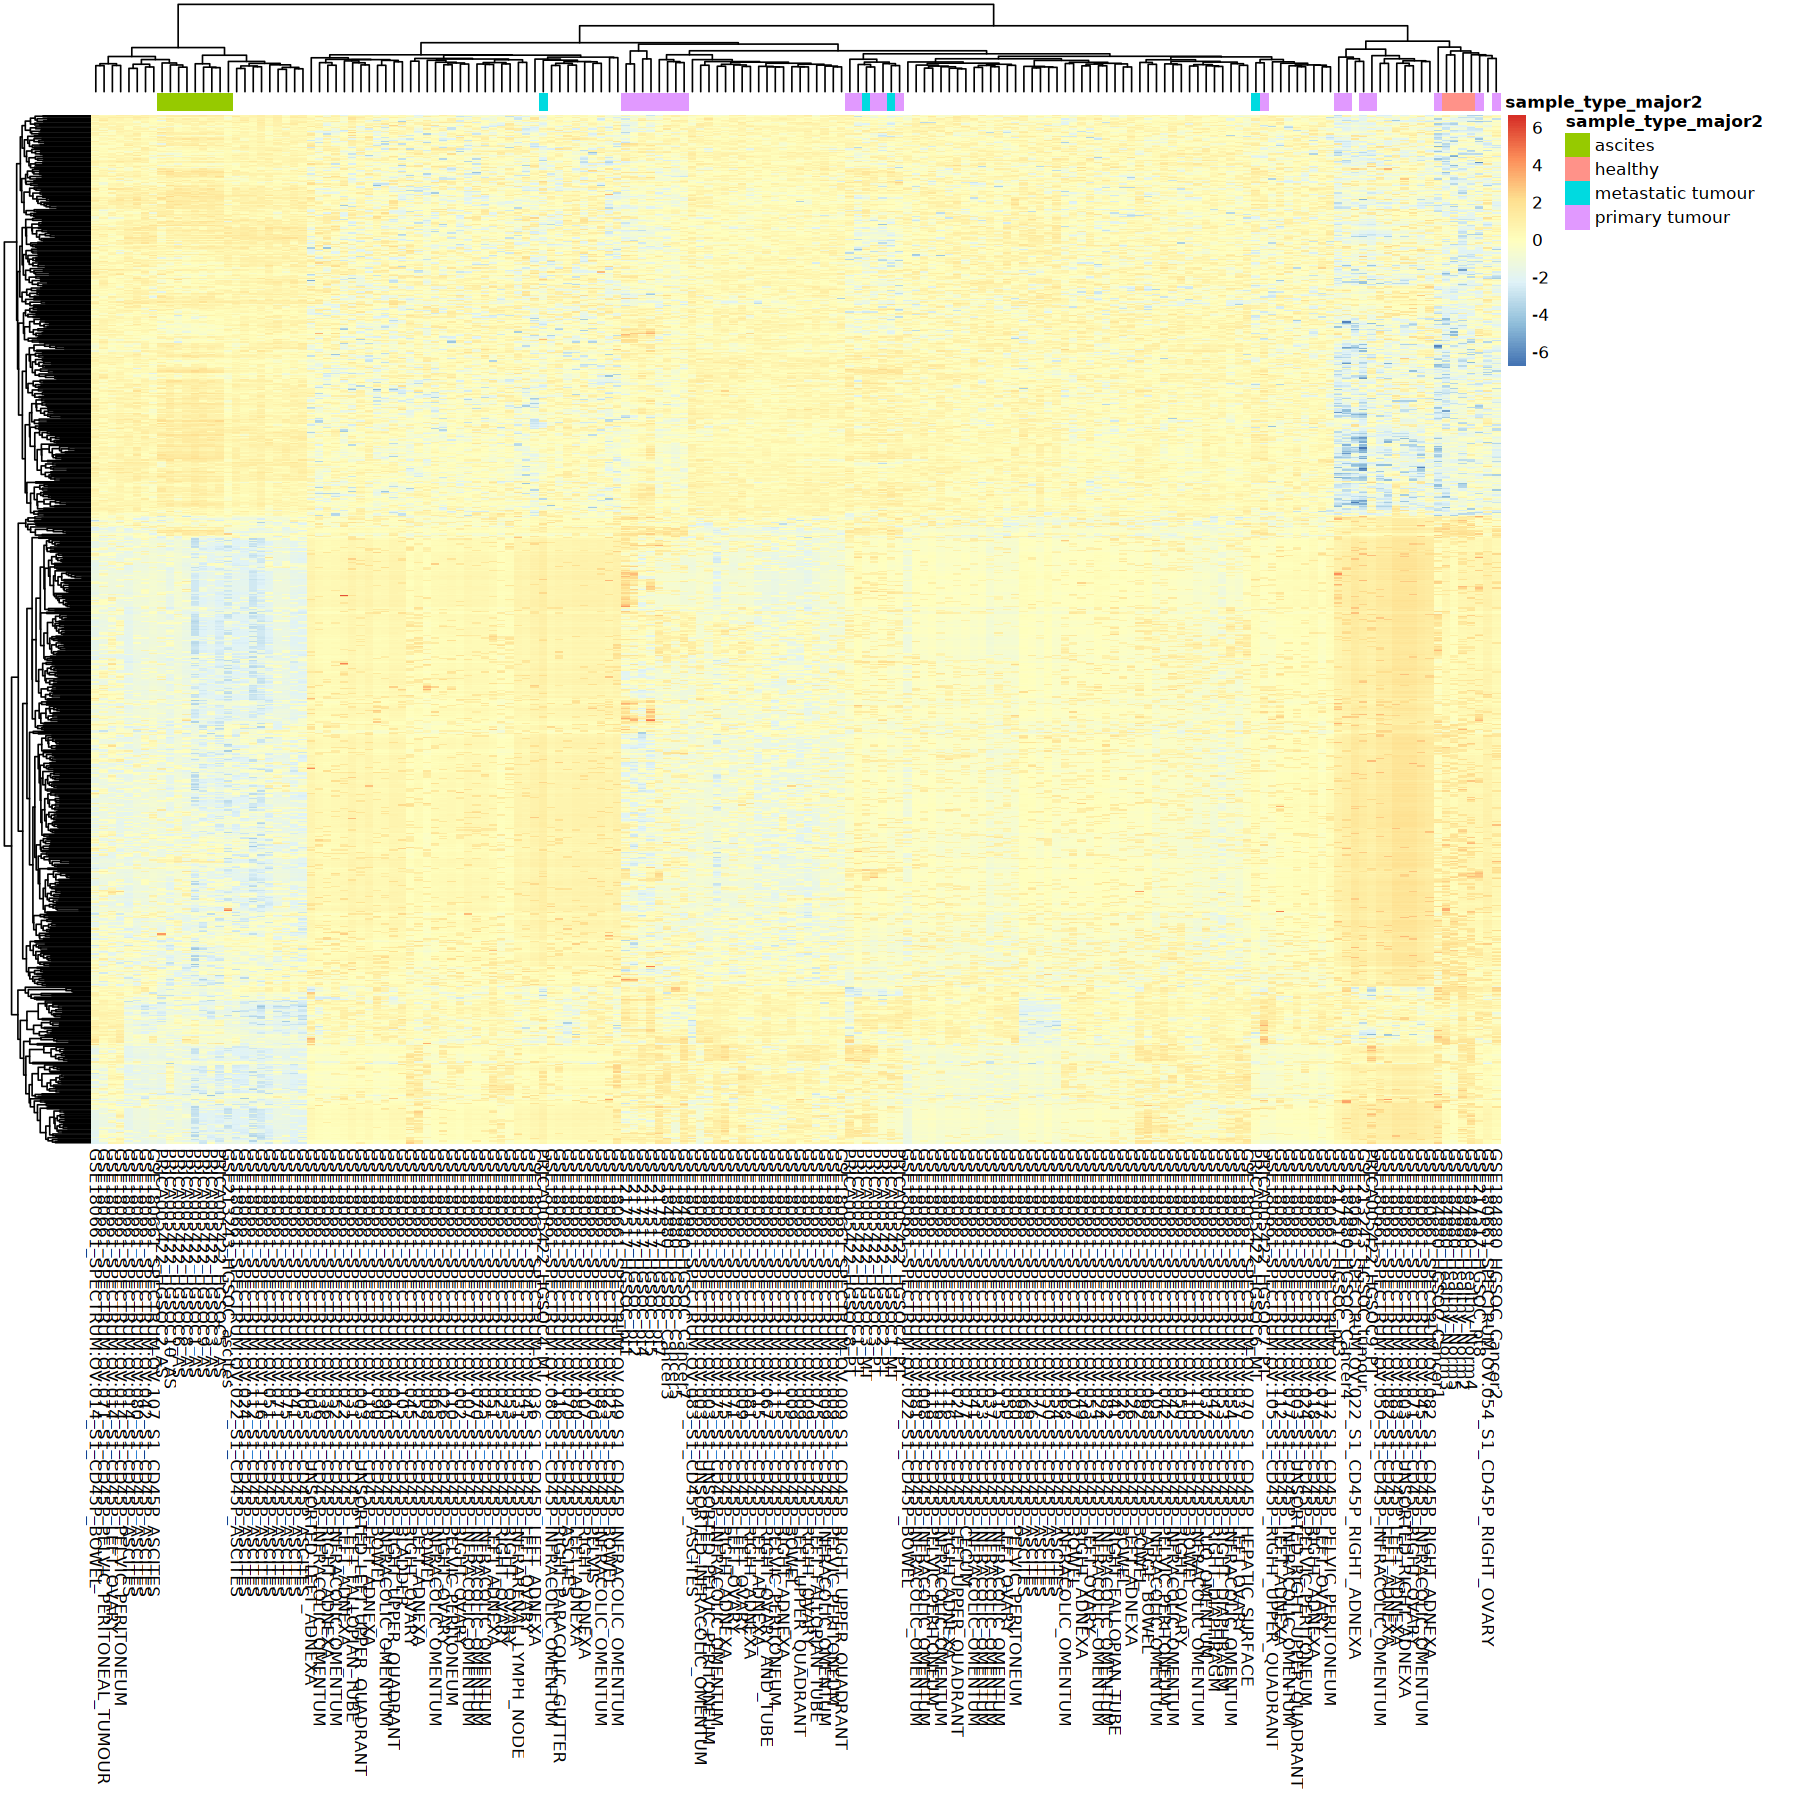

In [52]:
options(repr.plot.height=15, repr.plot.width=15)
pheatmap(mat_tt1, scale = "row", show_rownames = FALSE, annotation_col = sampleinfo[, "sample_type_major2", drop=FALSE])

## Look at select comparisons

In [53]:
dim(tt1) #tt1 is primary_tumour-metastatic_tumour?

[1] 9997    8

In [35]:
getwd()

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/Pseudobulk"

In [53]:
# export as csv
write.csv(tt1, "PT-MT_limma_dc1.csv", quote = FALSE, row.names = FALSE)

## Compare all contrasts

In [54]:
head(tt1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOSB,FOSB,14192,-6.296804,7.277445,-10.322329,2.602494e-20,2.601713e-16,35.15871
COL1A2,COL1A2,5834,-5.243841,2.816614,-8.639858,1.760841e-15,8.801562e-12,24.31056
CXCR4,CXCR4,2150,-4.698578,7.427939,-7.388013,3.917982e-12,1.305602e-08,17.13263
NR4A1,NR4A1,9530,-4.245668,7.017105,-7.087584,2.267957e-11,4.699024e-08,15.45282
COL1A1,COL1A1,12509,-4.794828,2.971580,-7.081416,2.350217e-11,4.699024e-08,15.33050
RGS1,RGS1,1265,-4.721053,7.965060,-6.953391,4.903455e-11,8.169973e-08,14.72184


In [56]:
# subgroup significant up and down degs from tt1
# 0.58 equivalent to 1.5 fold change
tt1_up_sig <- tt1[tt1$logFC > 0.58 & tt1$adj.P.Val < 0.05, ]
tt1_dn_sig <- tt1[tt1$logFC < -0.58 & tt1$adj.P.Val < 0.05, ]
# extract only the gene names
tt1_up_sig_list <- rownames(tt1_up_sig)
tt1_dn_sig_list <- rownames(tt1_dn_sig)

#tt1 here is primary vs metastatic

# subgroup significant up and down degs from tt2
# 0.58 equivalent to 1.5 fold change
tt2_up_sig <- tt2[tt2$logFC > 0.58 & tt2$adj.P.Val < 0.05, ]
tt2_dn_sig <- tt2[tt2$logFC < -0.58 & tt2$adj.P.Val < 0.05, ]
# extract only the gene names
tt2_up_sig_list <- rownames(tt2_up_sig)
tt2_dn_sig_list <- rownames(tt2_dn_sig)

#tt2 here is primary vs healthy

# subgroup significant up and down degs from tt8
# 0.58 equivalent to 1.5 fold change
tt3_up_sig <- tt3[tt3$logFC > 0.58 & tt3$adj.P.Val < 0.05, ]
tt3_dn_sig <- tt3[tt3$logFC < -0.58 & tt3$adj.P.Val < 0.05, ]
# extract only the gene names
tt3_up_sig_list <- rownames(tt3_up_sig)
tt3_dn_sig_list <- rownames(tt3_dn_sig)

#tt3 here is primary vs ascites

In [57]:
tt1_up_sig_list

[1] "LY96"      "FLOT1"     "GCA"       "REST"      "MIF4GD"    "RAB32"    
  [7] "CST7"      "TMEM59"    "ARL6IP5"   "TMEM219"   "MRPS34"    "SLC46A3"  
 [13] "LRRCC1"    "CCNI"      "SPINT2"    "CCPG1"     "XCR1"      "PCMTD1"   
 [19] "ATP6V0E1"  "RCN2"      "ERLEC1"    "FUCA1"     "PTGES2"    "PTPN1"    
 [25] "UFC1"      "PARP1"     "NAAA"      "MAGEF1"    "S100A11"   "CTSH"     
 [31] "NUBPL"     "MFF"       "GAS6"      "XRN2"      "SEC11A"    "TMEM9B"   
 [37] "SEPHS2"    "P2RY6"     "PON2"      "CFDP1"     "DCTPP1"    "COMMD8"   
 [43] "ARPC2"     "SDHA"      "ARF5"      "CLNK"      "ITGB1"     "SERPINB1" 
 [49] "MRPL54"    "PNMA1"     "ZDHHC24"   "PTMS"      "RHOA"      "DUSP23"   
 [55] "ADAP2"     "UQCRFS1"   "STX17"     "EVL"       "M6PR"      "PLEKHB2"  
 [61] "RABAC1"    "SMARCA5"   "EIF3F"     "TOMM7"     "NUP50"     "HLA-E"    
 [67] "CD72"      "MAP3K13"   "SOD1"      "PRCP"      "CCDC127"   "NCF1"     
 [73] "CD226"     "RAB31"     "CLTB"      "PSMB5"     "FAM50A"    "PLEKHA3"  
 [79] "CCDC28A"   "CSNK2A1"   "LYPLA1"    "ALDH2"     "VPS41"     "ZNF22"    
 [85] "MTDH"      "ZNF366"    "GSTK1"     "ACAA1"     "GLIPR1"    "CHMP4B"   
 [91] "MYL6"      "GLRX3"     "PARP9"     "RNASET2"   "FBXO7"     "PARM1"    
 [97] "COMMD6"    "PMM1"      "NDUFS3"    "ZNF106"    "DDX24"     "UQCRC2"   
[103] "OS9"       "TRADD"     "MAN1A2"    "RTCB"      "PTPRE"     "FBXO27"   
[109] "ALKBH7"    "TACSTD2"   "KTN1"      "FTL"       "TRANK1"    "SYPL1"    
[115] "TUSC2"     "JOSD2"     "THRAP3"    "C7orf50"   "GINM1"     "ANXA7"    
[121] "LSM14A"    "WIPI2"     "SLAMF8"    "TMEM14B"   "SMCO4"     "GUSB"     
[127] "SS18L2"    "HDAC3"     "TMED4"     "SPCS1"     "SYNRG"     "ARPC1A"   
[133] "FIBP"      "USP14"     "ZNF580"    "NDUFB5"    "HLA-DQA1"  "POP7"     
[139] "CD1D"      "LMO4"      "MORF4L1"   "TXNL1"     "SNX22"     "EIF6"     
[145] "POLR3GL"   "RAD23B"    "HLA-C"     "MRPL33"    "UBAC1"     "SRP54"    
[151] "PYURF"     "SERPINF2"  "SH3BGRL"   "OSTF1"     "CBR1"      "RGS10"    
[157] "PSME3"     "PPA1"      "ATP6V0B"   "BRK1"      "TMEM258"   "PPCS"     
[163] "AKR7A2"    "NDUFA1"    "MCM5"      "GTF2F1"    "PARP4"     "YWHAH"    
[169] "LSM10"     "EIF2S2"    "MGST3"     "RPS8"      "EIF3L"     "SERPINF1" 
[175] "SKAP2"     "ZNF148"    "HLA-DOB"   "PLCG2"     "ROGDI"     "TMX1"     
[181] "PLBD2"     "CHIC2"     "PSMD2"     "SNAPC5"    "SGK3"      "VAMP5"    
[187] "ANAPC16"   "RER1"      "RABL6"     "MPHOSPH10" "SEC14L1"   "CNIH1"    
[193] "DCAF13"    "SEL1L3"    "NOL7"      "PIH1D1"    "LAMTOR5"   "CTSB"     
[199] "CD93"      "CAT"       "DCUN1D1"   "C1orf122"  "SDHC"      "TALDO1"   
[205] "B3GNTL1"   "RPL10"     "NAA38"     "BAG1"      "COA1"      "PSMB9"    
[211] "JTB"       "COPB1"     "CPNE3"     "CDC40"     "KIF2A"     "CD47"     
[217] "IGBP1"     "PRDX3"     "ETFA"      "ARIH2"     "LGALS3"    "TGS1"     
[223] "C1orf21"   "CLNS1A"    "ODC1"      "PEF1"      "ARL3"      "DNAJC4"   
[229] "ARL6IP4"   "GSPT1"     "MYCL"      "SERPINB6"  "DCTN2"     "ALG5"     
[235] "PDAP1"     "CYB5R3"    "FBXL15"    "PAK1"      "TSPAN3"    "ACP5"     
[241] "IQGAP1"    "RAB5C"     "BIRC2"     "CSF2RA"    "VMO1"      "COX5B"    
[247] "MTPN"      "HMGN1"     "KDELR1"    "SF3B1"     "C4orf3"    "HLA-DPB1" 
[253] "PIGT"      "LEPROTL1"  "MYEF2"     "GLO1"      "RPS27"     "UBE2J1"   
[259] "APLP2"     "TLR8"      "NCOA4"     "PPT1"      "RNF115"    "CTCF"     
[265] "RNF181"    "SKP1"      "MDH2"      "BCCIP"     "YWHAG"     "FKBP8"    
[271] "SEC11C"    "LITAF"     "NOSIP"     "SNHG8"     "CRLF3"     "DYM"      
[277] "EEF1D"     "GPAA1"     "GDI2"      "WDR41"     "U2AF1L4"   "STOML2"   
[283] "DNAJC3"    "EHF"       "NUDT16"    "ACAA2"     "LAP3"      "CALCRL"   
[289] "EEF1A1"    "AGPAT1"    "MSRB1"     "CTBS"      "RPS26"     "BNIP2"    
[295] "MBD4"      "ATP10D"    "PMVK"      "OLA1"      "MBP"       "C1orf54"  
[301] "TMEM179B"  "RPS6KB2"   "PPP1R12A"  "APPL1"     "DDI2"      "CCNDBP1"  
[307] "LSM2"      "TSPAN

In [58]:
tt1_dn_sig_list

[1] "FOSB"       "COL1A2"     "CXCR4"      "NR4A1"      "COL1A1"    
  [6] "RGS1"       "SLC2A3"     "GADD45B"    "SPARC"      "DUSP1"     
 [11] "MYL9"       "AURKB"      "HSPA1B"     "C11orf96"   "PHGDH"     
 [16] "CDCA3"      "RASD1"      "TAGLN"      "SKA3"       "IER5"      
 [21] "COL3A1"     "POLR2J3"    "CCL4"       "FOXM1"      "HSPA1A"    
 [26] "KIF15"      "NR4A2"      "HIST2H2AB"  "PRC1"       "NRARP"     
 [31] "BHLHE40"    "E2F8"       "HIST1H3G"   "CCL4L2"     "CDKN3"     
 [36] "ZWINT"      "SPAG5"      "LETM2"      "CDC20"      "DNAJB1"    
 [41] "CKAP2L"     "NOD2"       "ARL4A"      "DIAPH3"     "GPR183"    
 [46] "ZNF367"     "C1S"        "TNFSF9"     "RRM2"       "RGS2"      
 [51] "TPM2"       "NME7"       "ZFP36"      "ABCF2"      "BUB1"      
 [56] "KCTD3"      "RCN3"       "CENPF"      "ESCO2"      "FOSL2"     
 [61] "DCUN1D2"    "IGFBP4"     "MXD3"       "MND1"       "SPC25"     
 [66] "CEP55"      "MCM10"      "GTSE1"      "ZBTB18"     "TOP2A"     
 [71] "ZSCAN25"    "MGP"        "MKI67"      "TBC1D24"    "KLF4"      
 [76] "GINS1"      "WDR34"      "PLA1A"      "RECQL4"     "YTHDF3-AS1"
 [81] "CDC6"       "HIST1H2AJ"  "HBA2"       "DUSP2"      "CCNB2"     
 [86] "UBE2C"      "TTK"        "CCL2"       "HIST1H3A"   "PRR4"      
 [91] "C12orf75"   "CDCA2"      "E2F7"       "C19orf54"   "IER5L"     
 [96] "SYNJ2"      "NUF2"       "HJURP"      "SPDYA"      "CDT1"      
[101] "DEPDC1"     "MB21D2"     "TMEM88"     "UNC119B"    "ATP8B2"    
[106] "FZD1"       "CTSV"       "HBB"        "KIF4A"      "CCDC88C"   
[111] "IFRD1"      "TAGAP"      "LAPTM4B"    "CIT"        "ZHX3"      
[116] "TPX2"       "DUSP4"      "HSP90AA1"   "FOS"        "CENPM"     
[121] "CDCA8"      "NID1"       "ARHGEF39"   "YOD1"       "PHKG1"     
[126] "C21orf58"   "CAPS"       "DEPDC1B"    "CSRNP1"     "MELK"      
[131] "KLHL26"     "SPC24"      "CDK2AP1"    "CLDN4"      "THBS1"     
[136] "LDLR"       "ATXN7"      "SLC2A4RG"   "ITPR3"      "NPIPA1"    
[141] "AGAP6"      "CENPA"      "FBN1"       "HIST2H2BF"  "HK2"       
[146] "GALE"       "WDR35"      "IL7R"       "CDK2"       "DYRK3"     
[151] "DNAJB5"     "BLM"        "B3GNT5"     "JUND"       "RPGR"      
[156] "ARHGAP11A"  "E2F1"       "GGH"        "SPSB1"      "ID3"       
[161] "THBS3"      "SEC61A2"    "SMN1"       "SEMA3C"     "BRICD5"    
[166] "COQ3"       "FOXO1"      "ALKBH1"     "IL1R1"      "SKA1"      
[171] "CCNA2"      "PLK4"       "TYMS"       "RTTN"       "TROAP"     
[176] "ASF1B"      "ZSCAN12"    "POLQ"       "SIK1"       "PLD4"      
[181] "HAUS7"      "RGS13"      "SARM1"      "EIF5AL1"    "CCDC77"    
[186] "B4GALT2"    "CHEK1"      "CDC7"       "ERRFI1"     "BIRC5"     
[191] "KIF2C"      "MIR155HG"   "ZNF251"     "GLMN"       "PPP2R3B"   
[196] "CLU"        "TM4SF1"     "LINC00910"  "DNHD1"      "OIP5"      
[201] "MAD2L1"     "TMEM170B"   "CDK1"       "CD83"       "NFIX"      
[206] "ZNF358"     "PAPSS2"     "DTL"        "GRAMD1B"    "OTUD1"     
[211] "TK1"        "CXCL2"      "CRYAB"      "SLC30A1"    "IGFBP2"    
[216] "WDR62"      "TTLL5"      "FXYD6"      "PPP1R15A"   "AMZ1"      
[221] "CITED4"     "FHL2"       "RAD54L"     "PLCXD1"     "RAB4B"     
[226] "EMP1"       "BUB1B"      "MS4A1"      "RHPN1"      "ARSI"      
[231] "ANLN"       "SUMO4"      "HMMR"       "CDH1"       "MYEOV"     
[236] "ZNF154"     "NUCB2"      "AC144652.1" "KHDRBS3"    "SPTBN1"    
[241] "KIFC1"      "ADAT2"      "PTGS2"      "CDCA5"      "CCNE2"     
[246] "CLCF1"      "SCRIB"      "SNX24"      "ENGASE"     "TMCC3"     
[251] "KIF14"      "PHACTR1"    "ATAD5"      "ECE2"       "EZH2"      
[256] "RAI1"       "ANKMY1"     "SDR42E2"    "FBXL22"     "TULP2"     
[261] "MYBL2"      "DNAI2"      "MT1M"       "TNFRSF11A"  "HIST1H2BH" 
[266] "TRIM59"     "ANKRD55"    "MBOAT4"     "PDE4D"      "MT1E"      
[271] "RTN4IP1"    "CNBD2"      "OPTN"       "FBXO46"     "PHLPP1"    
[276] "CDC42EP4"   "KIF27"      "DHODH"      "RANBP17"    "PCOLCE"    
[281] "PABPC1L"    "RRAGD"

In [45]:
# Combine into dataframe 
#up_genes_lists <- list(primary_tumour-metastatic_tumour_up = tt1_up_sig_list, primary_tumour-healthy_up = tt2_up_sig_list, primary_tumour-ascites_up = tt3_up_sig_list)

In [59]:
# Combine into dataframe 
up_genes_lists <- list(PT_MT_up = tt1_up_sig_list, PT_H_up = tt2_up_sig_list, PT_A_up = tt3_up_sig_list)

In [60]:
# combine into dataframe
down_genes_lists <- list(PT_MT_dn = tt1_dn_sig_list, PT_H_dn = tt2_dn_sig_list, PT_A_dn = tt3_dn_sig_list)
     

In [61]:
# Convert to dataframe, filling missing values with NA
df_up_genes <- data.frame(lapply(up_genes_lists, function(x) { length(x) <- max(lengths(up_genes_lists)); x }))
df_down_genes <- data.frame(lapply(down_genes_lists, function(x) { length(x) <- max(lengths(down_genes_lists)); x }))
     

In [62]:
head(df_up_genes)

,PT_MT_up,PT_H_up,PT_A_up
,<chr>,<chr>,<chr>
1,LY96,SLC46A3,SLC46A3
2,FLOT1,CD1D,LRRCC1
3,GCA,UCP2,RGP1
4,REST,KCNK6,KCNK6
5,MIF4GD,LRRCC1,CD1D
6,RAB32,TSPAN2,XCR1


In [63]:
head(df_down_genes)

,PT_MT_dn,PT_H_dn,PT_A_dn
,<chr>,<chr>,<chr>
1,FOSB,FOSB,FOSB
2,COL1A2,RGS1,RGS1
3,CXCR4,CXCR4,CXCR4
4,NR4A1,DUSP4,DUSP4
5,COL1A1,NR4A2,NRARP
6,RGS1,NR4A1,DUSP1


In [72]:
# export to csv
write.csv(df_up_genes, "OC_DC1/df_up_genes.csv", quote = FALSE, row.names = FALSE)
write.csv(df_down_genes, "OC_DC1/df_down_genes.csv", quote = FALSE, row.names = FALSE)

In [64]:
class(tt1)

[1] "data.frame"

In [65]:
head(tt1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOSB,FOSB,14192,-6.296804,7.277445,-10.322329,2.602494e-20,2.601713e-16,35.15871
COL1A2,COL1A2,5834,-5.243841,2.816614,-8.639858,1.760841e-15,8.801562e-12,24.31056
CXCR4,CXCR4,2150,-4.698578,7.427939,-7.388013,3.917982e-12,1.305602e-08,17.13263
NR4A1,NR4A1,9530,-4.245668,7.017105,-7.087584,2.267957e-11,4.699024e-08,15.45282
COL1A1,COL1A1,12509,-4.794828,2.971580,-7.081416,2.350217e-11,4.699024e-08,15.33050
RGS1,RGS1,1265,-4.721053,7.965060,-6.953391,4.903455e-11,8.169973e-08,14.72184


In [66]:

write.csv(tt1, "OC_DC1/tt1_DC1.csv", quote = FALSE, row.names = TRUE)
write.csv(tt2, "OC_DC1/tt2_DC1.csv", quote = FALSE, row.names = TRUE)
write.csv(tt3, "OC_DC1/tt3_DC1.csv", quote = FALSE, row.names = TRUE)

In [4]:
tt1_DC1 <- read.csv("OC_DC1/tt1_DC1.csv", row.names = 1)

In [5]:
head(tt1_DC1)

,X,Symbol,logFC,AveExpr,t,P.Value,adj.P.Val,B
,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOSB,FOSB,14192,-6.296804,7.277445,-10.322329,2.602494e-20,2.601713e-16,35.15871
COL1A2,COL1A2,5834,-5.243841,2.816614,-8.639858,1.760841e-15,8.801562e-12,24.31056
CXCR4,CXCR4,2150,-4.698578,7.427939,-7.388013,3.917982e-12,1.305602e-08,17.13263
NR4A1,NR4A1,9530,-4.245668,7.017105,-7.087584,2.267957e-11,4.699024e-08,15.45282
COL1A1,COL1A1,12509,-4.794828,2.971580,-7.081416,2.350217e-11,4.699024e-08,15.33050
RGS1,RGS1,1265,-4.721053,7.965060,-6.953391,4.903455e-11,8.169973e-08,14.72184


## Performing GSEA using clusterprofiler

In [ ]:
#if (!require("BiocManager", quietly = TRUE))
 #   install.packages("BiocManager")
#
#BiocManager::install("clusterProfiler")


Bioconductor version '3.20' is out-of-date; the current release version '3.22'
  is available with R version '4.5'; see https://bioconductor.org/install

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.20 (BiocManager 1.30.27), R 4.4.3 (2025-02-28)

Installing package(s) 'clusterProfiler'

also installing the dependencies ‘tweenr’, ‘Biostrings’, ‘fastmatch’, ‘ggplotify’, ‘ggforce’, ‘ape’, ‘tidytree’, ‘treeio’, ‘R.oo’, ‘R.methodsS3’, ‘RSQLite’, ‘KEGGREST’, ‘fgsea’, ‘aplot’, ‘ggfun’, ‘ggnewscale’, ‘ggtangle’, ‘scatterpie’, ‘ggtree’, ‘R.utils’, ‘AnnotationDbi’, ‘DOSE’, ‘enrichplot’, ‘GO.db’, ‘GOSemSim’, ‘gson’, ‘qvalue’, ‘yulab.utils’


Warning message in install.packages(...):
“installation of package ‘ggtree’ had non-zero exit status”
Warning message in install.packages(...):
“installation of package ‘enrichplot’ had no

In [ ]:
#if (!require("BiocManager", quietly = TRUE))
 #   install.packages("BiocManager")
#
#BiocManager::install("org.Hs.eg.db")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.20 (BiocManager 1.30.27), R 4.4.3 (2025-02-28)

Installing package(s) 'org.Hs.eg.db'

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Old packages: 'backports', 'bit64', 'cli', 'cpp11', 'curl', 'devtools',
  'dplyr', 'ellipsis', 'fastDummies', 'fs', 'furrr', 'ggplot2', 'glue',
  'hardhat', 'igraph', 'lava', 'lazyeval', 'limma', 'lobstr', 'magrittr',
  'nlme', 'openssl', 'pak', 'parallelly', 'pkgload', 'processx', 'progressr',
  'ps', 'purrr', 'ragg', 'Rcpp', 'RcppArmadillo', 'recipes', 'rmarkdown',
  'rpart', 'S7', 'Seurat', 'SeuratObject', 'sourcetools', 'spatstat.explore',
  'spatstat.geom', 'spatstat.random', 'terra', 'textshaping', 'tinytex',
  'vctrs', 'vroom'



In [ ]:
#BiocManager::install("enrichplot")

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.20 (BiocManager 1.30.27), R 4.4.3 (2025-02-28)

Installing package(s) 'enrichplot'

also installing the dependency ‘ggtree’


Warning message in install.packages(...):
“installation of package ‘ggtree’ had non-zero exit status”
Warning message in install.packages(...):
“installation of package ‘enrichplot’ had non-zero exit status”
Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Old packages: 'backports', 'bit64', 'cli', 'cpp11', 'curl', 'devtools',
  'dplyr', 'ellipsis', 'fastDummies', 'fs', 'furrr', 'ggplot2', 'glue',
  'hardhat', 'igraph', 'lava', 'lazyeval', 'limma', 'lobstr', 'magrittr',
  'nlme', 'openssl', 'pak', 'parallelly', 'pkgload', 'processx', 'progressr',
  'ps', 'purrr', 'ragg', 'Rcpp', 'RcppArmadillo', 'recipes', 'rmarkdown

In [68]:
library(clusterProfiler)



clusterProfiler v4.14.0 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

T Wu, E Hu, S Xu, M Chen, P Guo, Z Dai, T Feng, L Zhou, W Tang, L Zhan,
X Fu, S Liu, X Bo, and G Yu. clusterProfiler 4.0: A universal
enrichment tool for interpreting omics data. The Innovation. 2021,
2(3):100141


Attaching package: ‘clusterProfiler’


The following object is masked from ‘package:stats’:

    filter




In [69]:
library(enrichplot)
library(dplyr)

enrichplot v1.26.1 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

Guangchuang Yu, Qing-Yu He. ReactomePA: an R/Bioconductor package for
reactome pathway analysis and visualization. Molecular BioSystems.
2016, 12(2):477-479



In [ ]:
#install.packages("msigdbr")

also installing the dependency ‘babelgene’


Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



In [59]:
install.packages("org.Hs.eg.db")

Warning message:
“package ‘org.Hs.eg.db’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


In [70]:
library(msigdbr)
library('org.Hs.eg.db')

Loading required package: AnnotationDbi

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following object is masked from ‘package:limma’:

    plotMA


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, saveRDS, setdiff,
    table, tapply, union, unique, unsplit, which.max, which.min


Loading required package: Biobase

Welcome to Bioconductor

    Vignettes contain introductory material; view with
    'browseVignettes()'

In [160]:
sessionInfo()

R version 4.4.3 (2025-02-28)
Platform: x86_64-conda-linux-gnu
Running under: Rocky Linux 9.7 (Blue Onyx)

Matrix products: default
BLAS/LAPACK: /home/uqlbukat/miniforge3/envs/R_env/lib/libopenblasp-r0.3.30.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Australia/Brisbane
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] org.Hs.eg.db_3.20.0  AnnotationDbi_1.68.0 IRanges_2.40.1      
 [4] S4Vectors_0.44.0     Biobase_2.66.0       BiocGenerics_0.52.0 
 [7] BiocManager_1.30.27  pheatmap_1.0.13      RColorBrewer_1.1-3  


## Show which genes sets will be used for the comparison

From the meeting with KR-NR-KT on 13/4/26
* IFN --> HALLMARK
* TNF --> HALLMARK
* Ag presentation --> KEGG
* Migration --> KEGG
* Phagocytosis --> KEGG

Load the packages to look at the KEGG and HALLMARK gene set pathways

In [63]:
msigdbr_species()

species_name,species_common_name
<chr>,<chr>
Anolis carolinensis,"Carolina anole, green anole"
Bos taurus,"bovine, cattle, cow, dairy cow, domestic cattle, domestic cow, ox, oxen"
Caenorhabditis elegans,NA
Canis lupus familiaris,"dog, dogs"
Danio rerio,"leopard danio, zebra danio, zebra fish, zebrafish"
Drosophila melanogaster,fruit fly
Equus caballus,"domestic horse, equine, horse"
Felis catus,"cat, cats, domestic cat"
Gallus gallus,"bantam, chicken, chickens, Gallus domesticus"


Gene setes to compare:
* inflammatory --> GOP_POSITIVE_REGULATION_OF_IMMUNE_RESPONSE
* regulatory --> GOP_NEGATIVE_REGULATION_OF_IMMUNE_RESPONSE


In [ ]:
#Load MsigDB  GO BP terms for homo sapiens
msig_go_bp <- msigdbr(species = "Homo sapiens", collection = "C5", subcollection = "GO:BP")

Warning message:
“The `category` argument of `msigdbr()` is deprecated as of msigdbr 10.0.0.
ℹ Please use the `collection` argument instead.”
Warning message:
“The `subcategory` argument of `msigdbr()` is deprecated as of msigdbr 10.0.0.
ℹ Please use the `subcollection` argument instead.”


ERROR: Error in curl::curl_download(url = release$zip_url, destfile = zip_path, : Timeout was reached [zenodo.org]:
Connection timed out after 10000 milliseconds


In [65]:
#Load MsigDB  GO BP terms for homo sapiens
msig_go_bp <- msigdbr(species = "Homo sapiens", collection = "C5", subcollection = "GO:BP")

ERROR: Error in curl::curl_download(url = release$zip_url, destfile = zip_path, : Timeout was reached [zenodo.org]:
Connection timed out after 10000 milliseconds


In [ ]:
# Extract the gene sets of interest
immune_go_terms <- msig_go_bp %>%
  filter(gs_name %in% c("GOBP_POSITIVE_REGULATION_OF_IMMUNE_RESPONSE",
                        "GOBP_NEGATIVE_REGULATION_OF_IMMUNE_RESPONSE"))